## Lab #3: Asking a statistical question
This week we are going to concentrate on asking a statistical question. This process almost always consists of 3+ steps:

1. Writing down in words very precisely what question you are trying to ask.
2. Translating the precise english question into a mathematical expression. This often includes determining the pdf of the background (possibly including trials), and the to integral to do to obtain a probability.
3. Coverting the probability into equivalent sigma

So in this lab we will assume that we know the form of the signal-free background distribution (determining a distribution from data will be next week's lab). In each of our three examples, your task will be to state the statistical question, convert it to math, then perform the associated analyses.

### Problem 1

In our first example we are looking at the temperature reading (meta-data) associated with an experiment. For the experiment to work reliably, the temperature should be at around 12 Kelvin, and if we look at the data it is mostly consistent with 12 Kelvin to within the 0.4 degree precision of the thermometry and the thermal control system (standard deviation). However, there are times when the thermal control system misbehaved and the temperature was not near 12 K, and in addition there are various glitches in the thermometry that give anomalously high and low readings (the reading does not match the real temperature). We definitely want to identify and throw out all the data when the thermal control system was not working (and the temperature was truly off from nominal). While it is possible to have an error in the thermometry such that the true temperature was fine, and we just had a wonky reading, in an abundance of caution we want to throw those values out too.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

To make this a bit concrete, we will simulate a little data. Start by simulating 100k 'good' data points assuming Gaussian fluctations, and because we are playing god adding the following 'bad' datapoints: {10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}

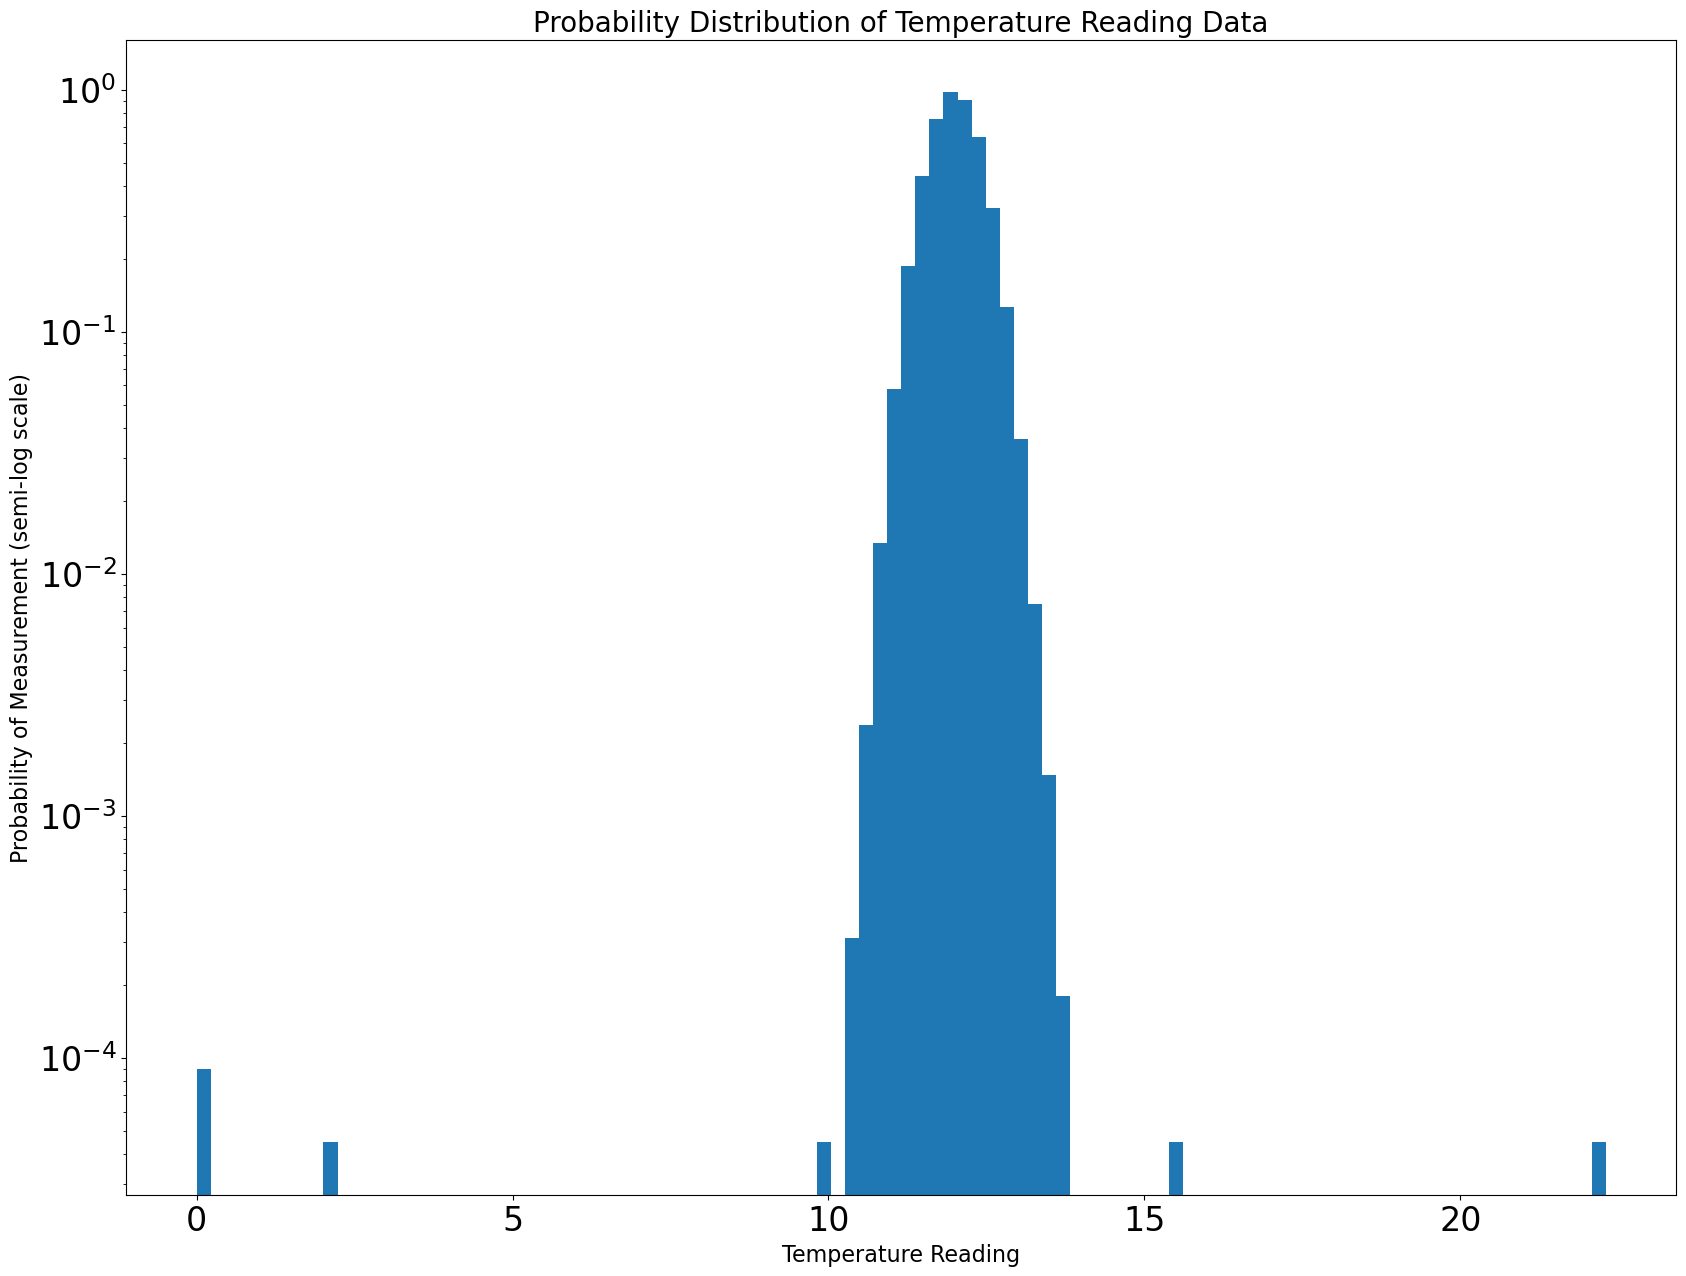

In [8]:
# Creating data, good and bad
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])

# plotting
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.xlabel("Temperature Reading", fontsize=16)
plt.ylabel("Probability of Measurement (semi-log scale)", fontsize=16)
plt.title("Probability Distribution of Temperature Reading Data", fontsize=20)
plt.show()

#### A) So our goal is to identify bad data and throw it out.

1. Start by exploring the data you have created with appropriate plots
2. State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.
3. Restate your question in math. Be very clear.
4. Apply your statistical test and construct a truth table.
	
The idea is how often you kept the known good data (True T & Your Test Good), how often you correctly discarded bad data (Bad T & Your Test Bad), and how often mistakes were made of either omission or commission (off diagonals).


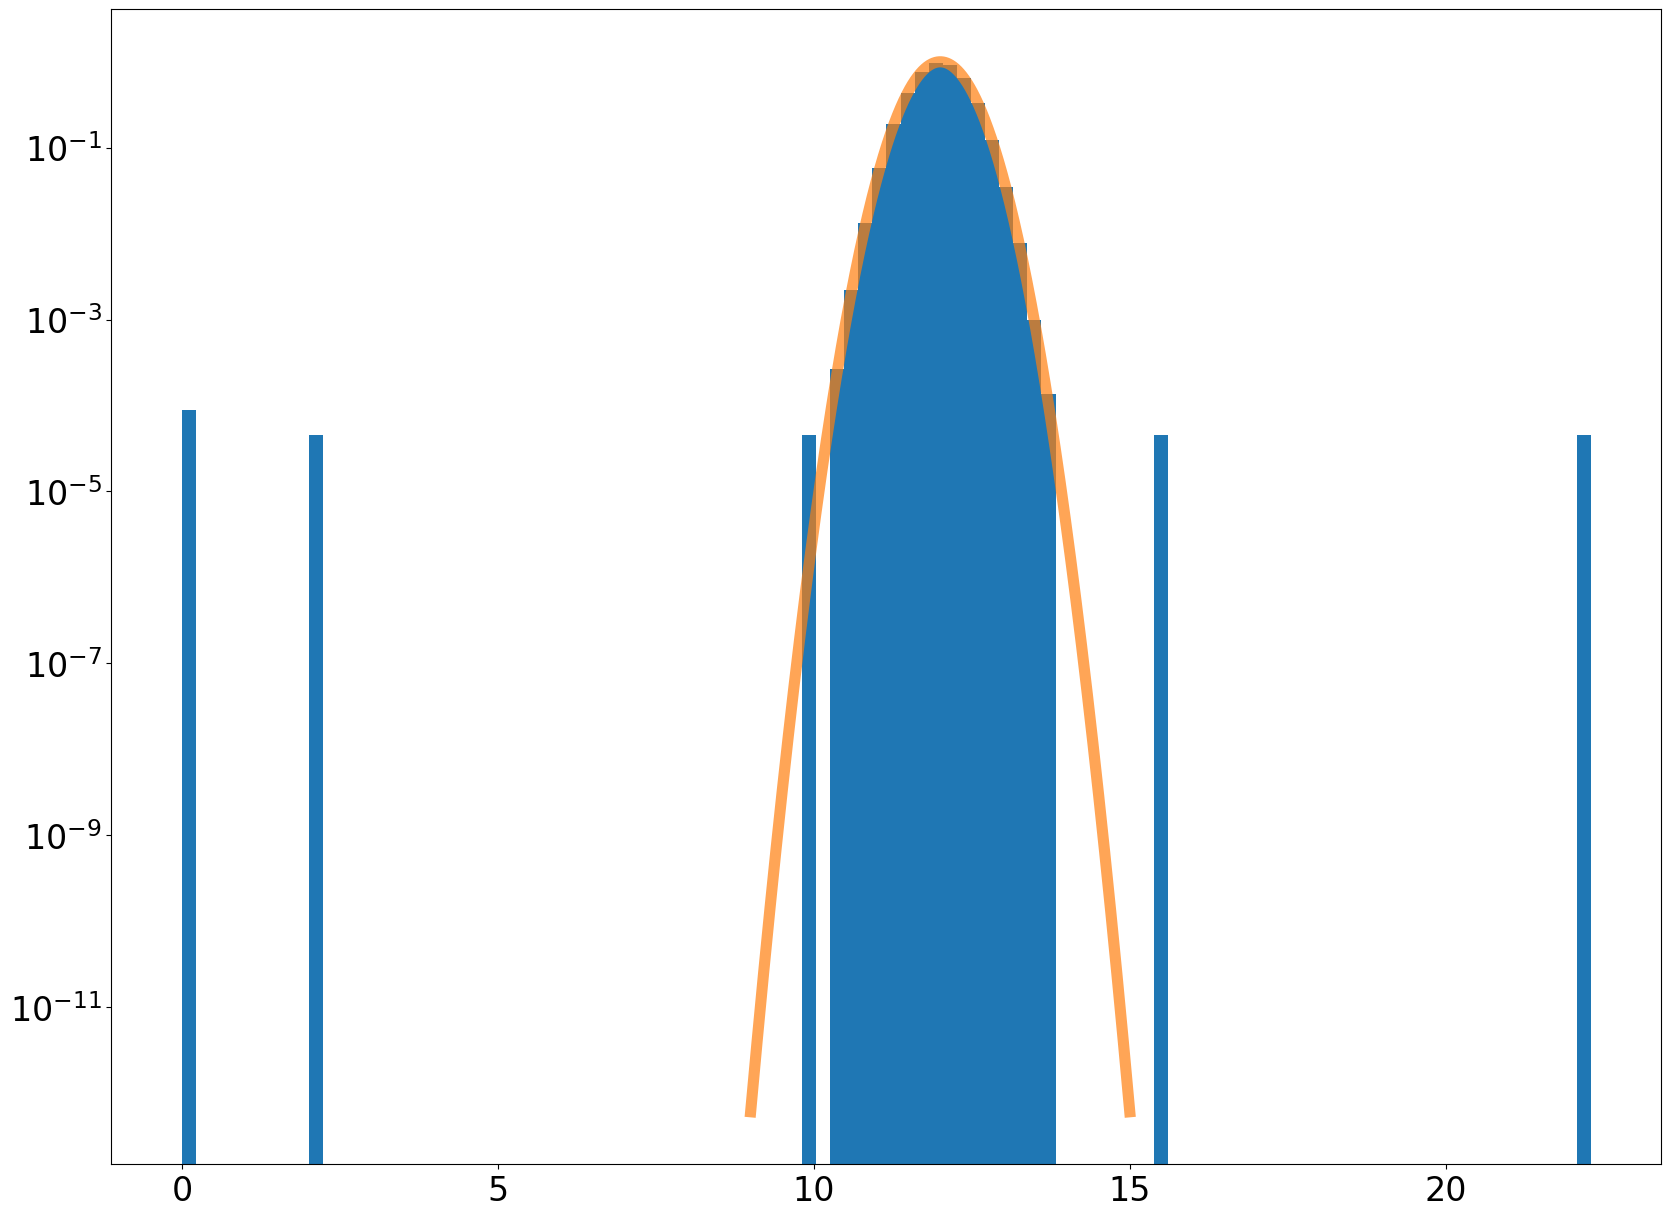

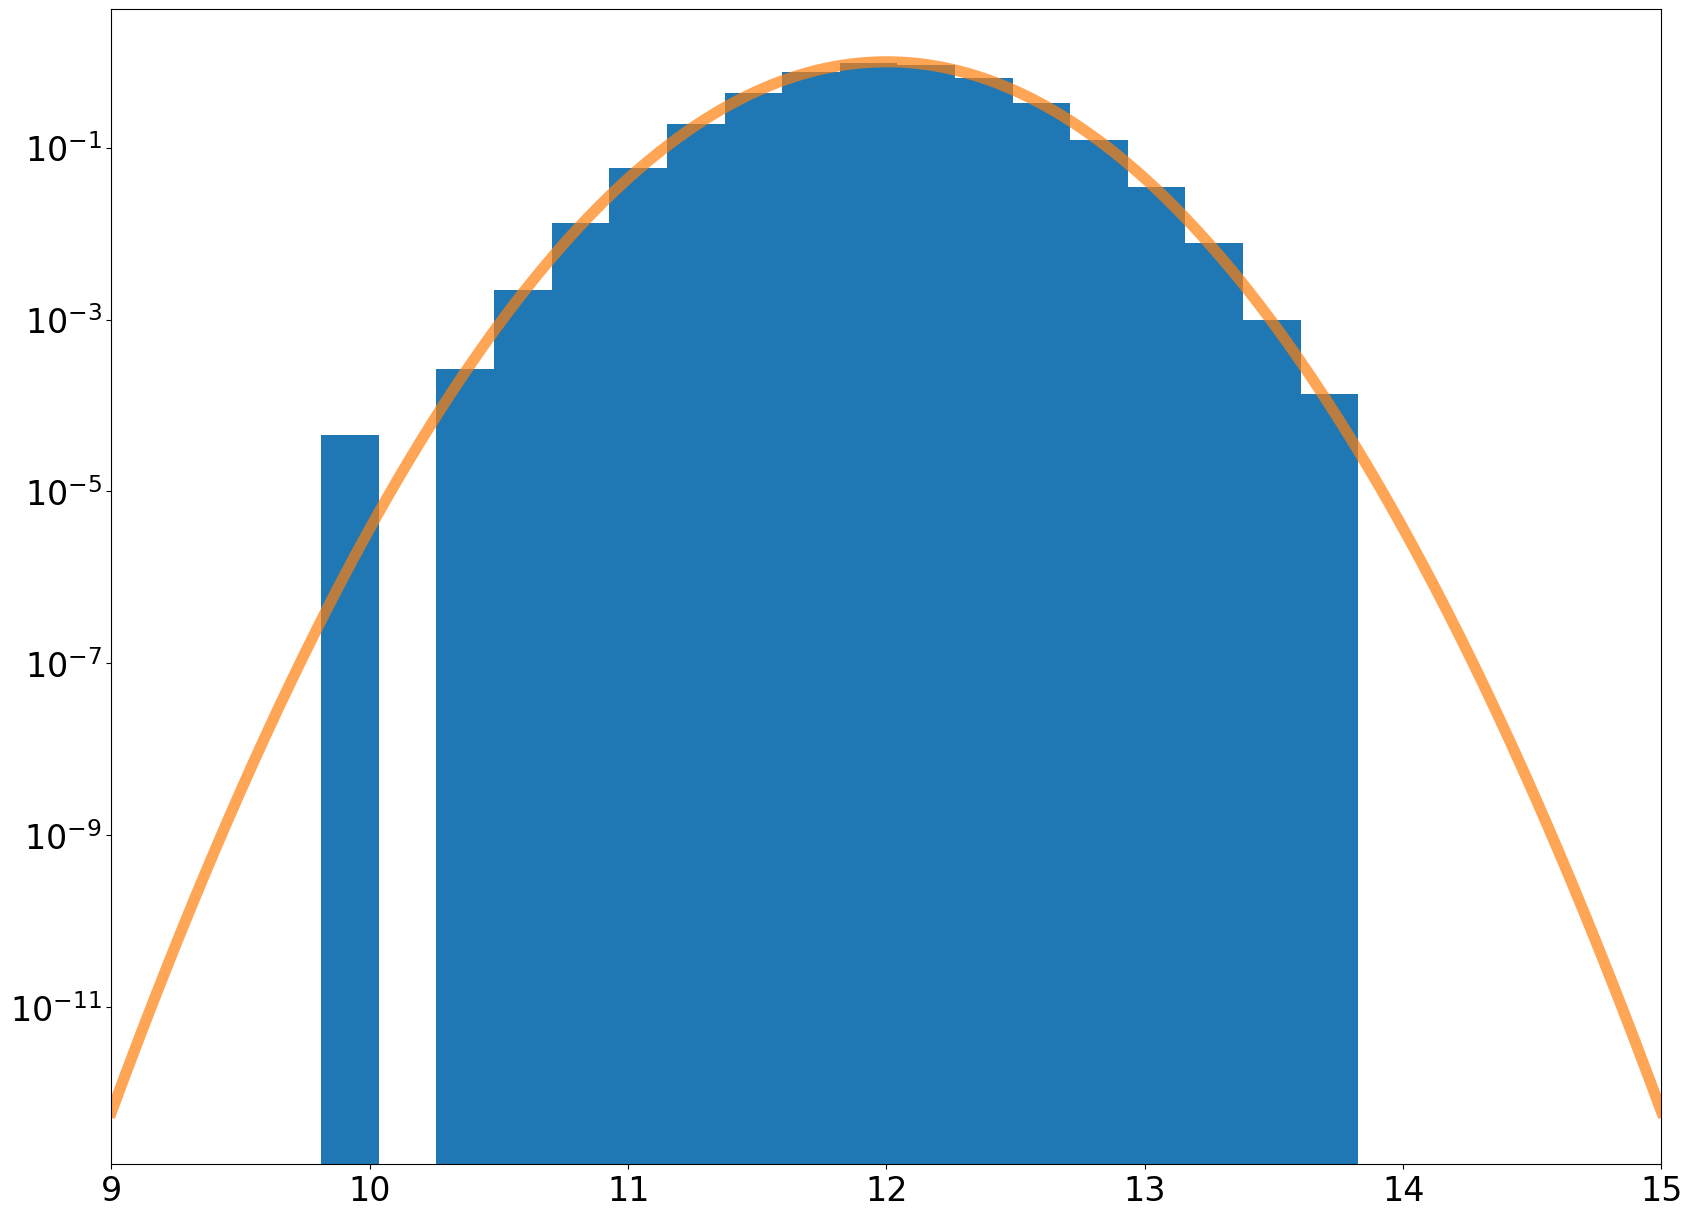

In [5]:
# Code for A) 1. 

# Plot showing data probability distribution as histogram and a plotted Gaussian pdf centered at 12 K with scale .4 K
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
x = np.linspace(9,15,1000)
ax.plot(x,stats.norm.pdf(x,loc = 12, scale = 0.4),linewidth = 8,alpha = 0.7)
plt.show()

# Plot showing data and plotted Gaussian fit to 12 K with scale .4 K zoomed into smaller range without largest outliers
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
x = np.linspace(9,15,1000)
ax.plot(x,stats.norm.pdf(x,loc = 12, scale = 0.4),linewidth = 8,alpha = 0.7)
ax.set_xlim(9, 15)
plt.show()


#### Answer to A) 2. Statistical Question

Statistical Question: How likely is it that a temperature measurement will produce a much lower or much higher temperature than 12 K


Question Restated in Math: The probability a single data point will be measured as being outside a given temperature bound is equal to two times the value of the survival function evaluated at some bound. The survival function only calculates the probability a value equal to or greater than the given bound is measured, and since we want to know the probability values much greater or much less than 12 K are measured, than we can simply multiply by 2 since the lower bounded values will have the same probability of being measured as the upper bounded ones, assuming our true data distribution of interest and bounds are symmetric about the mean of said distribution. 


In [23]:
# Our statistical test will consider a bound set at the value that for our true temperature data distribution corresponds to
# the value of 5 sigma for the standard normal. Data points within this bound and the symmetric to the mean lower bound will be 
# labeled as Your_Test_Good and points outside as Your_Test_Bad. Then since we know the bad data, we will construct a truth table
# labeling whether the data that passed the test was actually good or if it was bad, and the same is done to the data that did not
# pass the test. 


# First, the probability corresponding to 5 sigma is calculated. 
prob_5_sigma = stats.norm.sf(5, loc=0, scale=1)

# The probability from above is used to find the upper cutoff for the true measurment temperature distribution
upper_cutoff = stats.norm.isf(prob_5_sigma, loc=12, scale=.4)


# A lower cutoff is calculated using the fact the data probability distribution is symmetric about the mean. 
lower_cutoff = - upper_cutoff + 2 * 12


d_reduced = []

# Bad data listed again
T_True_Bad = [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]

# good data is listed
T_True = list(set(d) - set(T_True_Bad))

# setting up lists for truth tables
Test_good = []
Test_bad = []

Test_good_and_true = []
Test_good_and_bad = []
Test_bad_and_true = []
Test_bad_and_bad = []

# For every value in the data, if it is inside the bounds it is tested as good, and otherwise it is tested as bad
for n in np.arange(len(d)):
    if d[n] > lower_cutoff and d[n] < upper_cutoff:
        Test_good.append(d[n])
    else:
        Test_bad.append(d[n])

# for the data that tested as bad, if it is in the list of bad data it is labeled as such, and if it is not in the list, it is
# labeled as true.
for i in np.arange(len(Test_bad)):
    if set([Test_bad[i]]).issubset(T_True_Bad):
        Test_bad_and_bad.append(Test_bad[i])
    else:
        Test_bad_and_true.append(Test_bad[i])

# For the data that is good, if it is not in the bad data it is labeled as true
for i in np.arange(len(Test_good)):
    if set([Test_good[i]]).issubset(T_True_Bad):
        Test_good_and_bad.append(Test_good[i])
    else:
        Test_good_and_true.append(Test_good[i])


In [24]:
from tabulate import tabulate
data = [
    ["Your Test Good", len(Test_good_and_true), len(Test_good_and_bad) ],
    ["Your Test Bad", len(Test_bad_and_true), len(Test_bad_and_bad)]
]

headers = ["Test", "True T", "False T"]
print(tabulate(data, headers=headers, tablefmt="grid"))



+----------------+----------+-----------+
| Test           |   True T |   False T |
+================+==========+===========+
| Your Test Good |   100000 |         2 |
+----------------+----------+-----------+
| Your Test Bad  |        0 |         6 |
+----------------+----------+-----------+


#### B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

Our statistical threshold was based on the probability of equal or similar measurements being more extreme (farther from the mean and the given measurement), so as we lower the threshold, it means we increase the number of omissions. The omissions are predictable if we know the true data, as when we lower the threshold we throw out any values that are equally far from the mean as the threshold or farther from the mean. If we don't know the true data, then we can predict how many values are omitted based on the distribution, but with finite sampling it will not be perfect.

#### C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

In my test, there is bad data getting in because I have set the statistical threshold too high. They can be avoided by decreasing the statistical threshold so that more data is thrown out, but this has the chance of throwing out good data.



### Problem 2

In this example we will be looking for asteroids. If we look at the alignment of stars on subsequent images, they don't perfectly align due to atmospheric and instrumental effects (even ignoring proper motion). The resulting distribution is two dimensional, and for this lab let's assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if I histogram how far all the (stationary) stars appear to have moved I get something like:

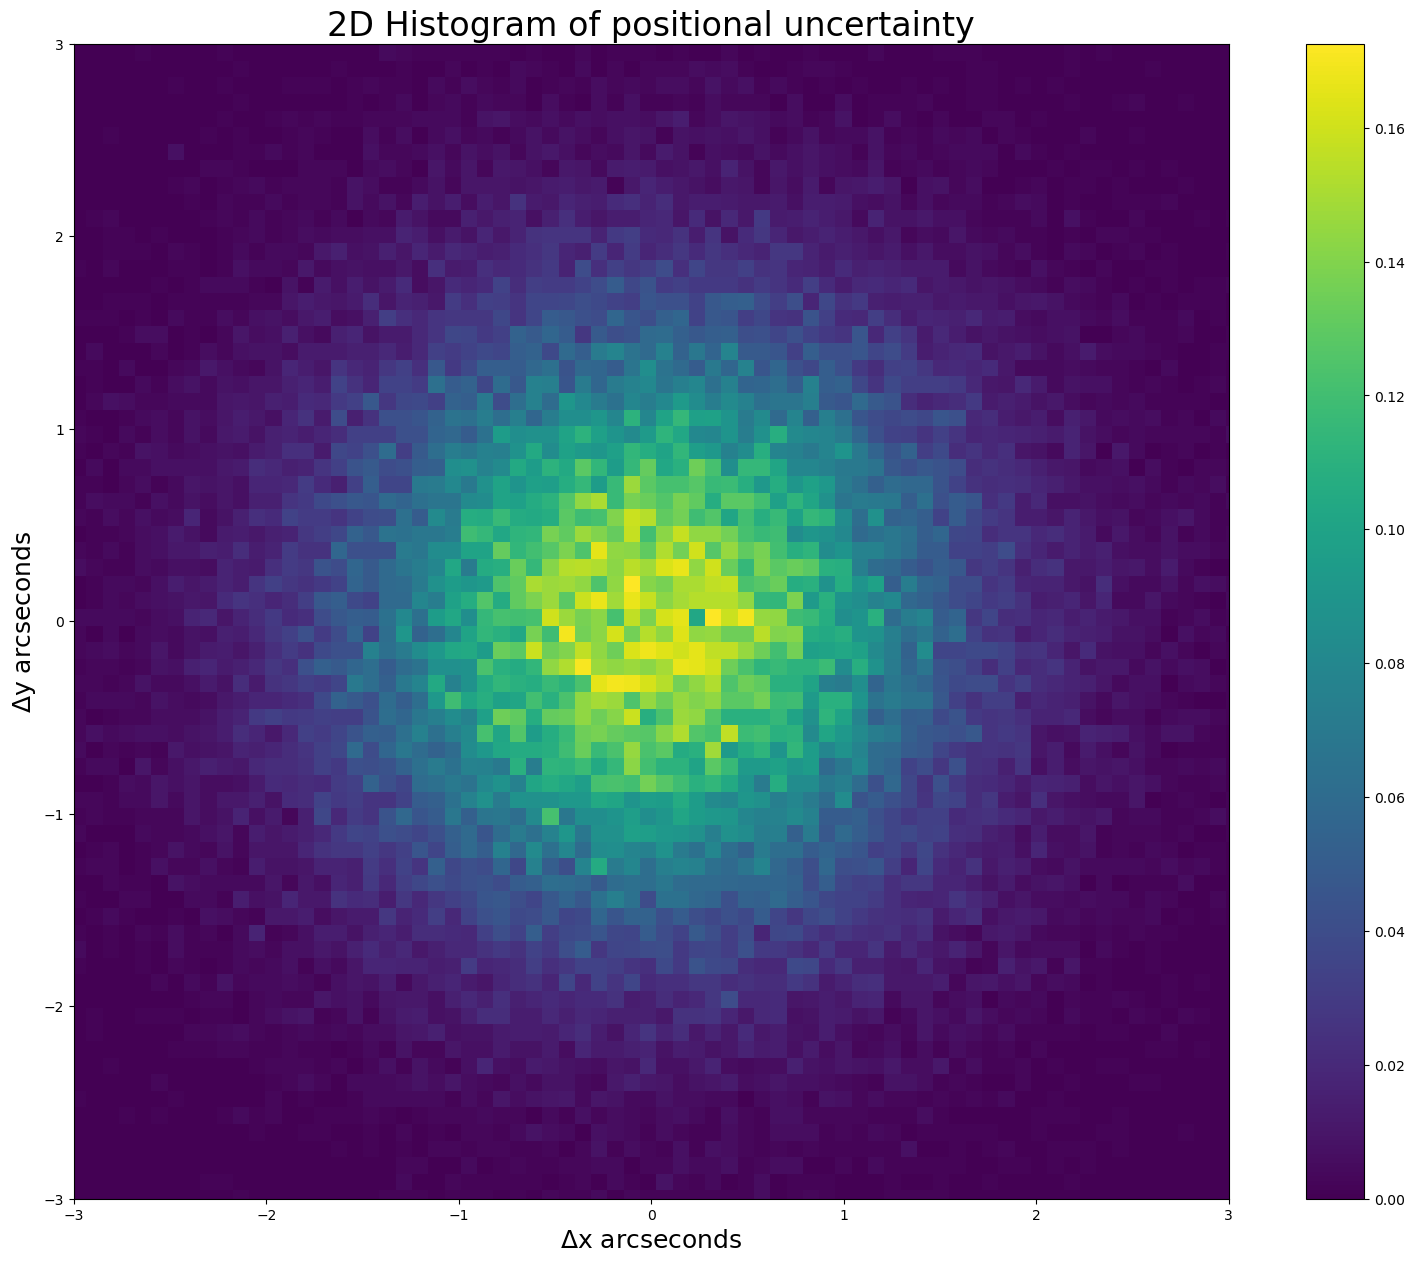

In [25]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta $y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta $x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds?

1. What is the question in words?
2. What is the question in math? [Hint: Come up with an analytic description of your pdf(). The Blue Book may be helpful here.]
3. What distance in arcseconds represents a 5 sigma detection of motion?

Question in Words: We want to know the chance that a given measurement from the pdf of the magnitude of the 2D Gaussian is greater than 5 sigma

Question in Math: We want to find the probability that a Rayleigh distribution gives 5 sigma and the associated value that bounds the 5 sigma probability value 


In [26]:
# First getting the probability of 5 sigma measurement
prob_5_sigma = stats.norm.sf(5, loc=0, scale=1)

# Plugging this value into the inverse survival function of the rayleigh distribution function to get the value bounding the
# 5 sigma associated probability from the left
arc_s = stats.rayleigh.isf(prob_5_sigma, loc=0, scale=1)
print(arc_s)


5.489079776062419


Distance that represents a 5 sigma detection of motion: 5.489 arcseconds

### Problem 3

As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

As always:

1. What is the question in words?
2. Translate the question to math, describing both the expected background pdf() and the integral you need to do.
3. Convert to sigma.
   
There are some unique aspects to this problem. Make sure you explore them in your explanation.

Statistical Question: What is the probability that the number of observed cosmic rays could produce 6800 counts of measured rays or fewer?

Equivalent Mathematical Question: What is the probability in terms of sigma that as few our fewer rays than 6800 could be counted given a Poisson distribution over the 15 days we take measurements for 8 hours a night given a rate of 1 cosmic ray per minute?

In [28]:
# Solving problem to get sigma
number_min = 7200 # 15 * 8 * 60 = 7200
mu = 7200 * 1 # rate for poisson pdf

# getting percent chance that 6800 counts or less are measured. We use cdf as this gives the percent chance a given value is equal
# to or less than this value from the left.
percent = stats.poisson.cdf(6800, mu, loc=0)

# To get the associated sigma value we use the .isf() of the standard normal distribution as this tells us the associated sigma
# from a small percentage. 
sigma = stats.norm.isf(percent)

print(f"Associated sigma value is:{sigma}")



Associated sigma value is:4.750747965777188


So the sigma value is less than 5, which is just below what we might consider being significant.